# Lumina & Co — performance des canaux marketing

Jour 3. Le CMO a lancé six campagnes entre l'été 2025 et l'été 2026, sur sept
canaux. Il reçoit chaque semaine des rapports contradictoires : le social lui dit
que tout va bien, Google aussi, mais les ventes ne suivent pas.

Ce notebook calcule les KPIs par canal — coût par acquisition, coût d'acquisition
client, retour sur dépense publicitaire, taux de conversion — puis les classe. Le
point intéressant est que le classement change selon la métrique choisie, et
qu'aucune ne suffit seule.

## 1. Chargement et contrôles

Deux fichiers nouveaux : `touchpoints.csv`, une ligne par point de contact entre
la marque et un client, et `campaigns.csv`, les métriques déjà agrégées par
campagne. Ils étaient dans `data/raw/` depuis le premier jour mais n'avaient
jamais été ouverts.

Je réutilise aussi les fichiers nettoyés des jours précédents, parce que le
revenu et les dates d'achat doivent venir des transactions réelles.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 130)

DOSSIER_BRUT = Path.cwd().parent / "data" / "raw"
DOSSIER_TRAITE = Path.cwd().parent / "data" / "processed"

In [2]:
df_touchpoints = pd.read_csv(
    DOSSIER_BRUT / "touchpoints.csv",
    parse_dates=["timestamp"],
    low_memory=False,
)
df_campagnes = pd.read_csv(DOSSIER_BRUT / "campaigns.csv")
df_transactions = pd.read_parquet(
    DOSSIER_TRAITE / "transactions_clean.parquet"
)
df_customers = pd.read_parquet(DOSSIER_TRAITE / "customers_clean.parquet")

print("touchpoints :", df_touchpoints.shape)
print("campagnes   :", df_campagnes.shape)
print("période     :", df_touchpoints["timestamp"].min().date(),
      "->", df_touchpoints["timestamp"].max().date())
print("parcours    :", df_touchpoints["journey_id"].nunique())
print("canaux      :", df_touchpoints["channel"].nunique())

touchpoints : (1080897, 13)
campagnes   : (6, 14)
période     : 2025-06-16 -> 2026-06-29
parcours    : 214897
canaux      : 7


In [3]:
cout_touchpoints = df_touchpoints["cost"].sum()
cout_campagnes = df_campagnes["total_cost"].sum()

print("coût total dans touchpoints : %12.0f €" % cout_touchpoints)
print("coût total dans campaigns   : %12.0f €" % cout_campagnes)
print("écart                       : %12.0f €"
      % (cout_touchpoints - cout_campagnes))

conversions = df_touchpoints[df_touchpoints["converted"] == 1].copy()
numeros = conversions["invoice_id"].astype("Int64")
conversions["invoice_id"] = numeros.astype(str)

factures_connues = set(df_transactions["invoice_id"])
clients_connus = set(df_customers["customer_id"])

print()
print("conversions :", len(conversions))
print("dont rattachées à une facture réelle :",
      conversions["invoice_id"].isin(factures_connues).sum())
print("clients de touchpoints présents dans customers : %d / %d"
      % (df_touchpoints["customer_id"].isin(clients_connus).sum() > 0
         and df_touchpoints["customer_id"].nunique(),
         df_touchpoints["customer_id"].nunique()))

coût total dans touchpoints :      1348008 €
coût total dans campaigns   :      1348008 €
écart                       :            0 €



conversions : 94366


dont rattachées à une facture réelle : 94366
clients de touchpoints présents dans customers : 49054 / 49054


Les deux fichiers de campagne sont cohérents entre eux : le coût total de
`touchpoints.csv` est exactement celui de `campaigns.csv`, à l'euro près. C'est
rassurant après les problèmes de réconciliation du premier jour.

Les jointures fonctionnent aussi : les 94 366 conversions renvoient toutes vers
une facture qui existe dans le fichier nettoyé, et tous les clients de
`touchpoints` sont dans le référentiel. On pourra donc calculer un revenu réel
plutôt que de faire confiance à une colonne agrégée.

Un détail de structure à noter tout de suite : `invoice_id` n'est renseigné que
sur les lignes de conversion, et `is_last_before_conversion` est strictement
identique à `converted`. Autrement dit **la ligne de conversion est le dernier
point de contact du parcours**. Ça servira demain pour le modèle last touch.

## 2. Les KPIs par canal

Quatre indicateurs, avec des définitions qu'il faut garder distinctes.

**Taux de conversion** : part des points de contact qui aboutissent à un achat.

**CPA**, coût par acquisition : dépense du canal divisée par le nombre de
conversions. Toute conversion compte, y compris le réachat d'un client déjà
fidèle.

**CAC**, coût d'acquisition client : dépense divisée par le nombre de **nouveaux**
clients seulement. Sur les mêmes données, le CAC est forcément plus élevé que le
CPA, puisqu'il porte sur un sous-ensemble plus petit de conversions pour un coût
identique.

**ROAS**, retour sur dépense publicitaire : revenu généré divisé par la dépense.

Je commence par ce qui ne demande pas de jointure.

In [4]:
kpi = df_touchpoints.groupby("channel").agg(
    touchpoints=("touchpoint_id", "size"),
    clics=("click", "sum"),
    conversions=("converted", "sum"),
    cout=("cost", "sum"),
)
kpi["ctr_pct"] = (kpi["clics"] / kpi["touchpoints"] * 100).round(1)
kpi["taux_conversion_pct"] = (kpi["conversions"] / kpi["touchpoints"]
                              * 100).round(2)
kpi["cpa"] = (kpi["cout"] / kpi["conversions"]).round(2)
kpi["cout"] = kpi["cout"].round(0)

COLONNES_BASE = ["touchpoints", "clics", "conversions", "cout", "ctr_pct",
                 "taux_conversion_pct", "cpa"]
kpi[COLONNES_BASE].sort_values("cout", ascending=False)

,touchpoints,clics,conversions,cout,ctr_pct,taux_conversion_pct,cpa
channel,,,,,,,
affiliate,54516,44884,26979,1128777.0,82.3,49.49,41.84
social,315763,142089,0,166324.0,45.0,0.00,inf
search_paid,41334,31548,13666,47264.0,76.3,33.06,3.46
email,150733,75666,14355,2263.0,50.2,9.52,0.16
retargeting,158102,83548,22563,1898.0,52.8,14.27,0.08
display,316530,142192,0,1482.0,44.9,0.00,inf
direct,43919,34441,16803,0.0,78.4,38.26,0.00


Trois anomalies sautent aux yeux, et chacune casse une partie du raisonnement
habituel.

**Display et social ne convertissent jamais.** Zéro conversion sur 316 530 et
315 763 points de contact, alors qu'ils totalisent environ 142 000 clics chacun.
Leur CPA vaut l'infini. Ils ne peuvent tout simplement pas être classés sur cette
métrique, et c'est déjà une réponse partielle au CMO : ses rapports de régie
social lui montrent des clics, pas des ventes.

**L'affiliation absorbe 84 % du budget.** 1 128 777 € sur 1 348 008 € au total,
pour 54 516 points de contact seulement. C'est le canal le plus cher de très
loin, avec un coût moyen de 20,71 € par contact contre moins d'un centime pour
l'email ou le retargeting.

**Le canal direct ne coûte rien.** Son CPA vaut zéro, ce qui en ferait
mécaniquement le meilleur canal de tous. C'est évidemment faux : le direct n'est
pas un canal d'acquisition qu'on achète, c'est le résultat de tout le reste.
Quelqu'un qui tape l'adresse du site y est arrivé parce qu'un autre canal l'a
fait connaître. Il faudra le sortir du classement de rentabilité.

### Le CAC, et pourquoi il faut repérer les primo-achats

Pour distinguer un nouveau client d'un réachat, il faut savoir si la facture
associée à la conversion est le premier achat de ce client. La conversion
référence un `invoice_id` : on récupère sa date dans les transactions, et on la
compare au `first_purchase` du client. Si les deux tombent le même jour, c'est un
primo-achat.

In [5]:
lignes_produit = df_transactions[df_transactions["est_ligne_produit"]]

revenu_par_facture = lignes_produit.groupby("invoice_id")["line_total"].sum()
date_par_facture = lignes_produit.groupby("invoice_id")["invoice_date"].min()
premier_achat = df_customers.set_index("customer_id")["first_purchase"]

conversions["revenu"] = conversions["invoice_id"].map(revenu_par_facture)
conversions["date_achat"] = conversions["invoice_id"].map(date_par_facture)
conversions["premier_achat"] = conversions["customer_id"].map(premier_achat)

meme_jour = (conversions["date_achat"].dt.normalize()
             == conversions["premier_achat"].dt.normalize())
conversions["primo_achat"] = meme_jour

print("conversions totales :", len(conversions))
print("dont primo-achats   :", conversions["primo_achat"].sum(),
      "(%.1f %%)" % (conversions["primo_achat"].mean() * 100))

conversions totales : 94366
dont primo-achats   : 1747 (1.9 %)


In [6]:
primo_par_canal = conversions.groupby("channel")["primo_achat"].sum()
revenu_par_canal = conversions.groupby("channel")["revenu"].sum()

kpi["primo_achats"] = primo_par_canal
kpi["revenu"] = revenu_par_canal
kpi["cac"] = (kpi["cout"] / kpi["primo_achats"]).round(2)
kpi["roas"] = (kpi["cout"].rdiv(kpi["revenu"])).round(2)

colonnes = ["cout", "conversions", "primo_achats", "cpa", "cac", "roas"]
kpi[colonnes].sort_values("cout", ascending=False).round(2)

,cout,conversions,primo_achats,cpa,cac,roas
channel,,,,,,
affiliate,1128777.0,26979,507.0,41.84,2226.38,4.70
social,166324.0,0,NaN,inf,NaN,NaN
search_paid,47264.0,13666,266.0,3.46,177.68,59.71
email,2263.0,14355,256.0,0.16,8.84,1149.36
retargeting,1898.0,22563,441.0,0.08,4.30,2345.51
display,1482.0,0,NaN,inf,NaN,NaN
direct,0.0,16803,277.0,0.00,0.00,inf


**Seulement 1,9 % des conversions sont des primo-achats**, 1 747 sur 94 366. Le
reste, ce sont des clients qui achetaient déjà. Le CAC est donc de l'ordre de
cinquante fois le CPA, ce qui est le signe que le filtre fonctionne — si les deux
chiffres avaient été proches, il aurait fallu suspecter une erreur.

Ce ratio dit déjà quelque chose au CMO : **ses campagnes touchent surtout des
clients existants**. Elles font du réachat, pas de l'acquisition. Ce n'est pas
forcément un défaut, mais ce n'est pas ce qu'on attend d'un budget publicitaire
présenté comme un investissement de croissance.

Le contraste est brutal sur l'affiliation. Son CPA de 41,84 € pouvait passer pour
acceptable. Son **CAC de 2 226 € pour un panier moyen de 195 €** ne passe pas du
tout. Il faudrait qu'un client acheté par ce canal commande une dizaine de fois
avant de rembourser son coût d'acquisition.

### Le revenu : celui de `campaigns.csv` ou celui des transactions ?

`campaigns.csv` fournit une colonne `revenue` toute prête. Le premier jour a
appris à s'en méfier, donc on compare avant de l'utiliser.

In [7]:
revenu_declare = df_campagnes["revenue"].sum()
revenu_recalcule = conversions["revenu"].sum()

print("revenu déclaré par campaigns   : %12.0f €" % revenu_declare)
print("revenu recalculé sur factures  : %12.0f €" % revenu_recalcule)
print("rapport : %.2f" % (revenu_recalcule / revenu_declare))
print()
print("panier moyen d'une conversion : %.2f €" % conversions["revenu"].mean())

revenu déclaré par campaigns   :      5560095 €
revenu recalculé sur factures  :     18383590 €
rapport : 3.31

panier moyen d'une conversion : 195.01 €


Un facteur 3,3 d'écart. C'est exactement le même problème que celui rencontré le
premier jour entre `total_spent` et les transactions : les colonnes agrégées de
ce jeu de données ne sont pas produites sur le même périmètre que les lignes de
détail.

Je garde le revenu recalculé, pour la même raison qu'au premier jour : chaque
euro est traçable jusqu'à une ligne de facture. Le ROAS du tableau précédent est
donc calculé sur cette base, et il est plus élevé que ce que `campaigns.csv`
laisserait croire.

## 3. Le classement dépend de la métrique

C'est le cœur de la question posée. On classe les canaux selon chaque métrique et
on regarde si l'ordre tient.

In [8]:
canaux_payants = kpi[kpi["cout"] > 0].copy()

classements = pd.DataFrame({
    "rang_cpa": canaux_payants["cpa"].rank(),
    "rang_cac": canaux_payants["cac"].rank(),
    "rang_roas": canaux_payants["roas"].rank(ascending=False),
    "rang_taux_conv": canaux_payants["taux_conversion_pct"].rank(
        ascending=False),
})
classements = classements.sort_values("rang_cpa")

print("rang 1 = le plus performant sur la métrique")
classements.round(1)

rang 1 = le plus performant sur la métrique


,rang_cpa,rang_cac,rang_roas,rang_taux_conv
channel,,,,
retargeting,1.0,1.0,1.0,3.0
email,2.0,2.0,2.0,4.0
search_paid,3.0,3.0,3.0,2.0
affiliate,4.0,4.0,4.0,1.0
display,5.5,NaN,NaN,5.5
social,5.5,NaN,NaN,5.5


Le classement ne tient pas d'une métrique à l'autre, et deux canaux illustrent
bien pourquoi.

**Les trois métriques de coût donnent exactement le même ordre** : retargeting,
email, search payant, affiliation. Ce n'est pas surprenant, elles partagent
toutes le coût du canal et se comportent donc de la même façon.

**Le taux de conversion renverse presque entièrement ce classement.**
L'affiliation passe de la dernière à la première place, l'email de la deuxième à
la dernière. Quand l'affiliation touche quelqu'un, ça marche une fois sur deux ;
simplement, chaque contact coûte 20,71 €. À l'inverse l'email ne transforme qu'un
contact sur dix, mais il ne coûte pratiquement rien.

Les deux lectures sont vraies. Un excellent taux de transformation sur un canal
hors de prix reste un mauvais investissement, et un mauvais taux sur un canal
gratuit reste rentable.

La conclusion pratique pour le CMO est qu'aucun classement unique n'existe. La
question n'est pas « quel est le meilleur canal » mais « meilleur pour quoi » : le
taux de conversion mesure l'efficacité d'un contact, le CPA mesure le coût d'une
vente, le CAC mesure le coût d'un client nouveau. Trois questions différentes.

Et deux canaux ne figurent nulle part dans ce tableau, display et social, parce
qu'ils n'ont aucune conversion à leur nom. Les juger sur ces métriques revient à
conclure qu'ils ne servent à rien. C'est ce que le notebook suivant va vérifier.

## 4. À quoi correspond `primary_channel` ?

`campaigns.csv` désigne un canal principal par campagne. Il serait tentant de le
lire comme « le canal qui a le mieux marché ». Vérifions en comparant à deux
autres définitions possibles : le canal le plus volumineux, et le canal qui
convertit le plus.

In [9]:
volume = df_touchpoints.pivot_table(index="campaign_name", columns="channel",
                                    values="touchpoint_id", aggfunc="size")
succes = conversions.pivot_table(index="campaign_name", columns="channel",
                                 values="touchpoint_id", aggfunc="size")

campagnes_indexees = df_campagnes.set_index("campaign_name")

comparaison = pd.DataFrame({
    "primary_channel": campagnes_indexees["primary_channel"],
    "plus_de_touchpoints": volume.idxmax(axis=1),
    "plus_de_conversions": succes.idxmax(axis=1),
})
comparaison["primary_est_le_volume"] = (
    comparaison["primary_channel"] == comparaison["plus_de_touchpoints"]
)
comparaison

,primary_channel,plus_de_touchpoints,plus_de_conversions,primary_est_le_volume
campaign_name,,,,
Back_to_School,social,social,affiliate,True
Black_Friday,display,display,email,True
Spring_Launch,display,display,retargeting,True
Summer_Sale,display,display,affiliate,True
Valentine,display,display,affiliate,True
Winter_Promo,display,display,direct,True


La réponse est nette : sur les six campagnes, `primary_channel` correspond à
chaque fois au canal qui a **le plus de points de contact**, jamais à celui qui
convertit le mieux. C'est une mesure de volume, pas de performance.

C'est probablement la source de la confusion du CMO. Cinq campagnes sur six ont
« display » comme canal principal, et le display est effectivement celui sur
lequel on a diffusé le plus. Mais son nombre de conversions directes est nul.
Lire ce champ comme un classement de performance conduirait à investir davantage
sur le canal le plus visible plutôt que sur le plus efficace.

## 5. Les métriques de vanité

Le nombre de points de contact, le nombre de clics, le coût et le nombre de
conversions sont, pris isolément, des métriques de vanité. Chacune est un chiffre
flatteur qui ne permet aucune décision.

Le display affiche 316 530 impressions et 142 192 clics — de loin les plus gros
chiffres du tableau. Présentés seuls dans un rapport de régie, ils donnent
l'impression d'une campagne qui fonctionne. Ils ne disent rien du chiffre
d'affaires. C'est exactement ce que le CMO reçoit toutes les semaines.

Le coût seul est tout aussi inutile : dépenser 1,1 M€ en affiliation n'est ni bon
ni mauvais en soi. Et le nombre de conversions ne veut rien dire sans savoir
combien elles ont coûté ni si ce sont de nouveaux clients.

Ce qui les transforme en KPI, c'est la **mise en rapport**. Les clics divisés par
les contacts donnent un taux de clic, mesure d'attractivité. Le coût divisé par
les conversions donne un CPA, mesure d'efficacité économique. Le coût divisé par
les seuls primo-achats donne un CAC, mesure du prix d'un client. Le revenu divisé
par le coût donne un ROAS, mesure de rentabilité. Une métrique devient un KPI
quand elle est rattachée à un objectif et qu'elle peut faire changer une
décision.

## 6. Le CAC ne suffit pas non plus : la valeur vie client

Un CAC élevé n'est pas disqualifiant en soi. Il l'est si le client acheté ne
rapporte jamais assez pour le rembourser. La comparaison utile est donc le
rapport entre la valeur vie du client et son coût d'acquisition, avec un seuil de
référence : un ratio d'au moins 3 pour une croissance saine.

J'applique la formule du cours sur les clients dont on connaît le canal
d'acquisition, c'est-à-dire ceux dont le primo-achat est passé par une conversion
tracée. Trois hypothèses à assumer : la dépense annualisée sert de rythme de
dépense, la durée de vie se déduit du taux de rétention, et je retiens une marge
de 40 %, ordre de grandeur courant en cosmétique vendue en direct.

In [10]:
MARGE_BRUTE = 0.40      # ordre de grandeur en cosmétique vendue en direct
ANCIENNETE_MINIMALE = 0.25   # 3 mois, pour ne pas diviser par une durée nulle

canal_acquisition = (
    conversions[conversions["primo_achat"]]
    .groupby("customer_id")["channel"].first()
)

ventes_clients = lignes_produit[lignes_produit["client_identifie"]]
date_reference = lignes_produit["invoice_date"].max()

profil = ventes_clients.groupby("client_rattache").agg(
    montant=("line_total", "sum"),
    commandes=("invoice_id", "nunique"),
    premier=("invoice_date", "min"),
)
anciennete_ans = (date_reference - profil["premier"]).dt.days / 365.25
profil["anciennete_ans"] = anciennete_ans.clip(lower=ANCIENNETE_MINIMALE)
profil["depense_annuelle"] = profil["montant"] / profil["anciennete_ans"]
profil["canal_acquisition"] = profil.index.map(canal_acquisition)

acquis = profil.dropna(subset=["canal_acquisition"])
print("clients dont le canal d'acquisition est connu :", len(acquis))

clients dont le canal d'acquisition est connu : 1689


In [11]:
valeur = acquis.groupby("canal_acquisition").agg(
    clients=("montant", "size"),
    depense_annuelle=("depense_annuelle", "median"),
    retention=("commandes", lambda s: (s >= 2).mean()),
)
valeur["duree_vie_ans"] = (1 / (1 - valeur["retention"])).round(2)
valeur["ltv"] = (valeur["depense_annuelle"] * valeur["duree_vie_ans"]
                 * MARGE_BRUTE).round(0)
valeur["cac"] = kpi["cac"]
cac_non_nul = valeur["cac"].replace(0, np.nan)
valeur["ltv_sur_cac"] = (valeur["ltv"] / cac_non_nul).round(2)

valeur.round(2)

,clients,depense_annuelle,retention,duree_vie_ans,ltv,cac,ltv_sur_cac
canal_acquisition,,,,,,,
affiliate,494,1772.31,0.59,2.46,1744.0,2226.38,0.78
direct,268,1339.52,0.58,2.37,1270.0,0.00,NaN
email,250,1578.86,0.61,2.55,1610.0,8.84,182.13
retargeting,423,1542.29,0.52,2.09,1289.0,4.30,299.77
search_paid,254,2028.62,0.54,2.17,1761.0,177.68,9.91


Le classement de l'étape précédente est renversé.

**L'affiliation tombe à 0,8.** En dessous de 1, ce qui veut dire qu'un client
acquis par ce canal rapporte moins, sur toute sa durée de vie, qu'il n'a coûté à
acquérir. Le seuil de référence est 3 : on en est très loin. Le ROAS de 4,7 qui
semblait correct masquait ce problème, parce qu'il rapportait la dépense au
revenu de **toutes** les conversions, dont 98 % sont des réachats de clients déjà
acquis. Autrement dit l'affiliation se fait créditer des ventes qu'elle n'a pas
générées.

**Le search payant est à 9,9**, largement au-dessus du seuil. C'est le seul canal
payant significatif qui tienne la comparaison.

**L'email et le retargeting affichent des ratios à trois chiffres**, mais il faut
les lire avec prudence : leur coût est si faible que le dénominateur est presque
nul. Ce sont des canaux qui exploitent une base déjà constituée, pas des canaux
d'acquisition. Leur ratio dit surtout qu'ils ne coûtent rien, ce qu'on savait.

**Le canal direct n'a pas de ratio** puisqu'il n'a pas de coût.

Une réserve à porter : ce calcul repose sur 1 689 clients seulement, ceux dont le
primo-achat est tracé. C'est 3,4 % de la base. Les ordres de grandeur sont
utilisables, la précision non.

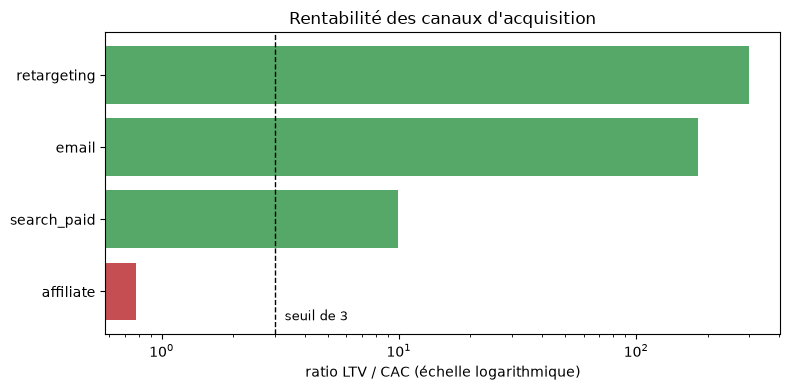

In [12]:
ratios = valeur["ltv_sur_cac"].dropna().sort_values()

figure, axe = plt.subplots(figsize=(8, 4))
couleurs = ["#c44e52" if r < 3 else "#55a868" for r in ratios]
axe.barh(ratios.index, ratios.values, color=couleurs)
axe.set_xscale("log")
axe.axvline(3, color="black", linestyle="--", linewidth=1)
axe.text(3.3, -0.4, "seuil de 3", fontsize=9)
axe.set_xlabel("ratio LTV / CAC (échelle logarithmique)")
axe.set_title("Rentabilité des canaux d'acquisition")
plt.tight_layout()
plt.show()

## Ce qu'on peut dire au CMO à ce stade

**Ses rapports de canal ne mesurent pas ce qu'il croit.** Le champ
`primary_channel` désigne le canal le plus diffusé, pas le plus performant. Les
chiffres que lui remontent les régies — impressions, clics — sont des métriques
de vanité tant qu'ils ne sont pas rapportés à un coût ou à un revenu.

**Ses campagnes font du réachat, pas de l'acquisition.** 98 % des conversions
sont le fait de clients qui achetaient déjà. C'est probablement la réponse à son
« je m'attendais à plus de ventes » : le budget tourne sur la base existante.

**L'affiliation est le premier arbitrage à faire.** 84 % du budget, un CAC de
2 226 €, un ratio valeur sur coût de 0,8. Aucune métrique de l'étape 1 ne le
montrait seule.

**Deux canaux restent hors de toute mesure**, display et social, qui n'ont aucune
conversion directe malgré 58 % des points de contact et 51 % des clics. Les
supprimer sur cette base serait une décision fondée sur leur absence dans un
tableau, pas sur leur inutilité. C'est le sujet du notebook suivant.

Une réserve de méthode, enfin. Un taux de conversion nul et parfaitement exact
sur deux canaux, sur plus de 600 000 points de contact, ne ressemble pas à un
comportement réel : c'est vraisemblablement une règle de construction du jeu de
données. Je raisonne donc sur ce que les chiffres permettent de démontrer, sans
affirmer que le display ne convertit jamais dans la vraie vie.